# Protein Function Prediction: End-to-End Skeleton
## Meeting 3 | Team 2

**Goal of this meeting:** a working end-to-end pipeline, not a meaningful prediction model.

The predictor:
1. reads a multi-protein FASTA file with `scikit-bio` (`skbio.io.read()`),
2. encodes sequences as one-hot tensors of shape `(B, N, D)` with a padding mask,
3. runs one dummy PyTorch model per Gene Ontology (BP, MF, CC) that returns random scores of shape `(B, P)`,
4. saves the predictions to a CSV file `ProteinID,GOterm,Score`.

```
FASTA -> read_fasta -> encode (one-hot + mask) -> 3 dummy models (BP, MF, CC) -> CSV
```

| File | Role |
|---|---|
| `src/pfp/vocab.py` | GO vocabularies per ontology (training terms only) |
| `src/pfp/data.py` | FASTA reading and sequence encoding |
| `src/pfp/models.py` | `DummyGOModel` |
| `src/pfp/predict.py` | Full pipeline, writes the CSV |

Each step is a separate file, so the encoding or the model can be replaced later without changing the rest.

In [1]:
import sys
import subprocess
import pandas as pd
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, "src/pfp")   # make data.py and models.py importable
from data import read_fasta, encode, AMINO_ACIDS, N, D, PAD_INDEX
from models import DummyGOModel

torch.manual_seed(42)
print("PyTorch:", torch.__version__)

PyTorch: 2.15.0+cpu


## 1. GO vocabularies

The output vectors must have the same length as the GO-term vocabularies from Meeting 2.
The Meeting 2 vocabulary contains all training GO terms together, so `vocab.py` splits it
into three files using the GO aspect (P = BP, F = MF, C = CC) from `label_evidence.tsv`.
Only training terms are used, so evaluation data does not influence the model outputs.

In [2]:
ONTOLOGIES = ["BP", "MF", "CC"]
vocabs = {}
for name in ONTOLOGIES:
    vocabs[name] = pd.read_csv(f"data/vocab/vocab_{name}.tsv")["go_id"].tolist()

pd.DataFrame({"Ontology": ONTOLOGIES,
              "GO terms (P)": [len(vocabs[n]) for n in ONTOLOGIES],
              "First term": [vocabs[n][0] for n in ONTOLOGIES]})

,Ontology,GO terms (P),First term
0,BP,2505,GO:0000001
1,MF,1607,GO:0000006
2,CC,720,GO:0000015


In [3]:
print("Total:", sum(len(v) for v in vocabs.values()), "GO terms")

Total: 4832 GO terms


## 2. Reading the FASTA file

`read_fasta()` uses `skbio.io.read()` and returns a list of `(protein ID, sequence)` pairs.
As input we use the test split from Meeting 2.

In [4]:
proteins = read_fasta("data/processed/splits/test.fasta")
lengths = [len(seq) for _, seq in proteins]

print("Proteins:", len(proteins))
print("Example:", proteins[0][0], proteins[0][1][:40], "...")
print("Shortest / longest sequence:", min(lengths), "/", max(lengths))
print("Longer than D = 1024 (truncated):", sum(l > D for l in lengths))

Proteins: 626
Example: A0A1D8PCX8 MSQVAPKWYQSEDVPAPKQTRKTARPQKLRASLVPGTVLI ...
Shortest / longest sequence: 17 / 3092
Longer than D = 1024 (truncated): 42


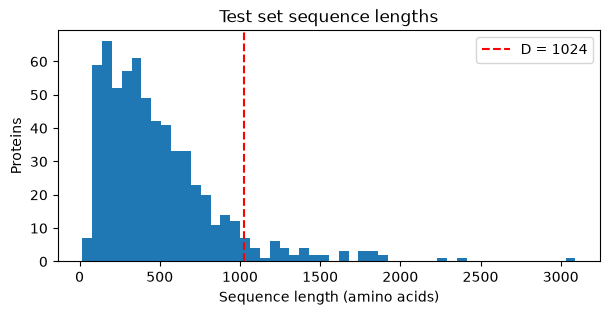

In [5]:
plt.figure(figsize=(7, 3))
plt.hist(lengths, bins=50)
plt.axvline(D, color="red", linestyle="--", label=f"D = {D}")
plt.xlabel("Sequence length (amino acids)")
plt.ylabel("Proteins")
plt.title("Test set sequence lengths")
plt.legend()
plt.show()

## 3. Encoding: one-hot tensor and mask

- Amino-acid vocabulary (N = 22): the 20 standard amino acids, `X` for unknown or non-standard residues, and `PAD` for padding.
- Maximum length D = 1024: shorter sequences are padded, longer ones are truncated.
- Input shape `(B, N, D)`: each protein is a 22 x 1024 table with one `1` per column.
- Mask shape `(B, D)`: `True` for real residues, `False` for padding positions.

Example with two short sequences (`U` is non-standard, so it is encoded as `X`):

In [6]:
x, mask = encode(["ACDXU", "MK"])
print("x shape:", x.shape)
print("mask shape:", mask.shape)

tokens = list(AMINO_ACIDS) + ["X", "PAD"]
first = pd.DataFrame(x[0, :, :7].int().numpy(), index=tokens,
                     columns=[f"pos {j}" for j in range(7)])
first.loc[(first != 0).any(axis=1)]   # show only rows that contain a 1

x shape: torch.Size([2, 22, 1024])
mask shape: torch.Size([2, 1024])


,pos 0,pos 1,pos 2,pos 3,pos 4,pos 5,pos 6
A,1,0,0,0,0,0,0
C,0,1,0,0,0,0,0
D,0,0,1,0,0,0,0
X,0,0,0,1,1,0,0
PAD,0,0,0,0,0,1,1


In [7]:
print("Mask of 'ACDXU' (first 7 positions):", mask[0, :7].tolist())
print("Mask of 'MK'    (first 7 positions):", mask[1, :7].tolist())

Mask of 'ACDXU' (first 7 positions): [True, True, True, True, True, False, False]
Mask of 'MK'    (first 7 positions): [True, True, False, False, False, False, False]


## 4. Dummy models

`DummyGOModel` is a PyTorch `nn.Module`. Its `forward(x, mask)` accepts the encoded batch and the
mask, like a real model will, but ignores them and returns random scores in [0, 1].
There is one model per ontology, and `P` is the size of its vocabulary.

Check on one batch of 32 test proteins:

In [8]:
models = {name: DummyGOModel(n_terms=len(vocabs[name])) for name in ONTOLOGIES}

batch = proteins[:32]
x, mask = encode([seq for _, seq in batch])
print("Input x:", tuple(x.shape), "  mask:", tuple(mask.shape))

for name in ONTOLOGIES:
    scores = models[name](x, mask)
    print(f"{name} output: {tuple(scores.shape)}   min = {scores.min():.4f}, max = {scores.max():.4f}")

Input x: (32, 22, 1024)   mask: (32, 1024)
BP output: (32, 2505)   min = 0.0000, max = 1.0000
MF output: (32, 1607)   min = 0.0000, max = 1.0000
CC output: (32, 720)   min = 0.0000, max = 1.0000


## 5. Running the full pipeline

The whole pipeline is run with one command. The same script works for any FASTA file.

In [9]:
result = subprocess.run([sys.executable, "src/pfp/predict.py",
                "--fasta", "data/processed/splits/test.fasta",
                "--out", "output/predictions_test.csv"], check=True)

Proteins: 626
Saved predictions to output/predictions_test.csv


In [10]:
predictions = pd.read_csv("output/predictions_test.csv")
predictions.head()

,ProteinID,GOterm,Score
0,A0A1D8PCX8,GO:0000001,0.8823
1,A0A1D8PCX8,GO:0000011,0.9150
2,A0A1D8PCX8,GO:0000017,0.3829
3,A0A1D8PCX8,GO:0000018,0.9593
4,A0A1D8PCX8,GO:0000019,0.3904


## 6. Checking the output

In [11]:
expected_rows = len(proteins) * sum(len(v) for v in vocabs.values())
rows_per_protein = predictions.groupby("ProteinID").size()

checks = pd.DataFrame([
    ["Rows in CSV", len(predictions), expected_rows],
    ["Proteins in CSV", predictions.ProteinID.nunique(), len(proteins)],
    ["GO terms per protein", rows_per_protein.min(), sum(len(v) for v in vocabs.values())],
    ["Scores in [0, 1]", predictions.Score.between(0, 1).all(), True],
], columns=["Check", "Result", "Expected"])
checks

,Check,Result,Expected
0,Rows in CSV,3024832,3024832
1,Proteins in CSV,626,626
2,GO terms per protein,4832,4832
3,"Scores in [0, 1]",True,True


## 7. Summary and next steps

**Done in Meeting 3:**
- A working FASTA -> CSV predictor with one dummy PyTorch model per ontology (BP: 2505, MF: 1607, CC: 720 terms).
- Input `(B, 22, 1024)` with a padding mask, output `(B, P)` per ontology.
- 626 test proteins x 4832 GO terms = 3,024,832 predictions.
- Fixed random seed (42), so the output is reproducible.

**Limitations:**
- Scores are random, so they carry no biological meaning yet.
- Only GO terms seen in training can be predicted; validation and test contain 220 and 236 terms absent from training.
- Sequences longer than 1024 residues are truncated.

**Next meeting (4):** evaluate the CSV with CAFA-evaluator (Fmax, weighted Fmax, Smin) per ontology.
Later, `DummyGOModel` will be replaced with a real model (e.g. ESM-2 embeddings + MLP) without changing the rest of the pipeline.